In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Voting Classifiers

In [2]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [3]:
X,y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=42)

In [4]:
voting_clf = VotingClassifier(
    estimators=[
        ("lr",LogisticRegression(random_state=42)),
        ("rf",RandomForestClassifier(random_state=42)),
        ("svc",SVC(random_state=42))
    ]
)

In [5]:
voting_clf.fit(X_train,y_train)

,estimators,"[('lr', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True


In [6]:
voting_clf.score(X_test,y_test)

0.912

In [7]:
for name, clf in voting_clf.named_estimators_.items():
    print(name,"=",clf.score(X_test,y_test))

lr = 0.864
rf = 0.896
svc = 0.896


In [8]:
voting_clf.predict([X_test[0]])

array([1])

In [9]:
[clf.predict([X_test[0]]) for clf in voting_clf.estimators_]

[array([1]), array([1]), array([0])]

In [10]:
# above 1 is highest voting so, voting_clf predicts 1

If all classifiers are able to estimate class probabilities (i.e., if they all have a
predict_proba() method), then you can tell Scikit-Learn to predict the class
with the highest class probability, averaged over all the individual classifiers.This is called soft voting.

In [11]:
voting_clf.voting = "soft"
voting_clf.named_estimators["svc"].probability = True # for svc we need to set. no need to set for remaing, voting_clf do for us after setting "soft"
voting_clf.fit(X_train,y_train)

voting_clf.score(X_test,y_test)

0.92

In [12]:
for name, clf in voting_clf.named_estimators_.items():
    print(name,"=",clf.predict_proba([X_test[0]]))

lr = [[0.49900001 0.50099999]]
rf = [[0.48 0.52]]
svc = [[0.56982947 0.43017053]]


In [13]:
voting_clf.predict_proba([X_test[0]])

array([[0.51627649, 0.48372351]])

In [14]:
(0.49900001+0.48+0.56982947)/3

0.5162764933333334

### Bagging and pasting

Bagging Data is sampled with replacement (instances can appear multiple times in a subset) \
Pasting: Data is sampled without replacement (each instance appears at most once in a subset).

In [15]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

In [17]:
bag_clf = BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=100,
    n_jobs=-1,
    random_state=42
)
# if you want to use pasting instead, just set bootstrap=False

In [18]:
bag_clf.fit(X_train,y_train)

,estimator,DecisionTreeClassifier()
,n_estimators,500
,max_samples,100
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,-1
,random_state,42
,verbose,0


In [19]:
bag_clf.score(X_test,y_test)

0.904

### Out-of-Bag Evaluation

With bagging, some training instances may be sampled several times for any
given predictor, while others may not be sampled at all. By default a
BaggingClassifier samples m training instances with replacement
(bootstrap=True), where m is the size of the training set. With this process, it
can be shown mathematically that only about 63% of the training instances
are sampled on average for each predictor.⁠  The remaining 37% of the
training instances that are not sampled are called out-of-bag (OOB) instances.
Note that they are not the same 37% for all predictors.A bagging ensemble can be evaluated using OOB instances, without the need
for a separate validation set

In [20]:
bag_clf = BaggingClassifier(
    DecisionTreeClassifier(),
    n_estimators=500,
    max_samples=100,
    n_jobs=-1,
    random_state=42,
    oob_score = True, # request an automatic OOB evaluation after training
)

In [21]:
bag_clf.fit(X_train,y_train)

,estimator,DecisionTreeClassifier()
,n_estimators,500
,max_samples,100
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,True
,warm_start,False
,n_jobs,-1
,random_state,42
,verbose,0


In [24]:
bag_clf.oob_score_

0.9253333333333333

In [25]:
# According to this OOB evaluation, this BaggingClassifier is likely to achieve about 92.5% accuracy on the test set

In [26]:
from sklearn.metrics import accuracy_score
y_pred = bag_clf.predict(X_test)
accuracy_score(y_test,y_pred)

0.904

In [27]:
# We get 90% accuracy on the test. The OOB evaluation was a bit too pessimistic, just over 2% too high.

In [28]:
bag_clf.oob_decision_function_[:3] # probas for the first 3 instances

array([[0.35579515, 0.64420485],
       [0.43513514, 0.56486486],
       [1.        , 0.        ]])

## Random Forests

In [ ]:
bag_clf = BaggingClassifier(
    DecisionTreeClassifier(max_features="sqrt", max_leaf_nodes=16), n_estimators=500, n_jobs=-1, random_state=42,oob_score=True)
)

In [35]:
# above bag_clf and below rnd_clf both are same

In [31]:
rnd_clf = RandomForestClassifier(
    n_estimators=500,
    max_leaf_nodes=16,
    n_jobs=-1,
    random_state=42,
    oob_score=True,
)

In [32]:
rnd_clf.fit(X_train,y_train)

,n_estimators,500
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,16
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [33]:
rnd_clf.oob_score_

0.9173333333333333

In [34]:
y_pred_rnd = rnd_clf.predict(X_test)

#### Feature importance

In [36]:
from sklearn.datasets import load_iris

In [37]:
iris= load_iris(as_frame=True)

In [38]:
rnd_clf = RandomForestClassifier(n_estimators=500,random_state=42)
rnd_clf.fit(iris.data,iris.target)

,n_estimators,500
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
for score, name in zip(rnd_clf.feature_importances_,iris.data.columns):
    print(round(score,2), name)

0.11 sepal length (cm)
0.02 sepal width (cm)
0.44 petal length (cm)
0.42 petal width (cm)


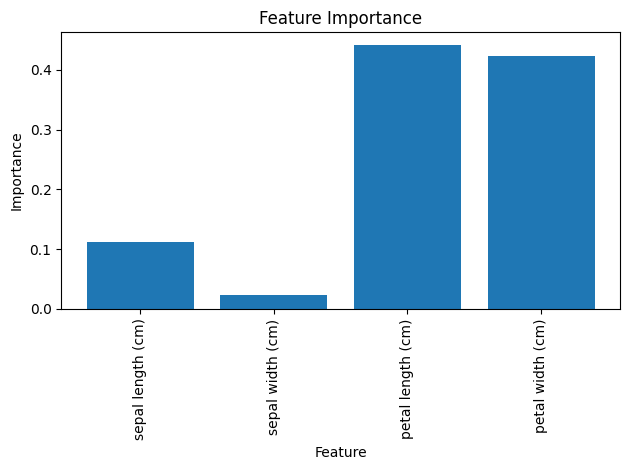

In [45]:
plt.bar(iris.data.columns,rnd_clf.feature_importances_)
plt.xticks(rotation=90)
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

### Adaboost

In [1]:
from sklearn.ensemble import AdaBoostClassifier

In [ ]:
ada_clf = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1),
    n_estimators=25,
    learning_rate=0.5,
    random_state=42
)
ada_clf.fit(X_train, y_train)

# Gradient Boosting

In [2]:
from sklearn.tree import DecisionTreeRegressor

In [3]:
# let’s generate a noisy quadratic dataset
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3 * X[:, 0] ** 2 + 0.05 * np.random.randn(100)  # y = 3x² + Gaussian noise

In [9]:
tree_reg1 = DecisionTreeRegressor(max_depth=2,random_state=42)
tree_reg1.fit(X,y)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


Now let's train another decision tree regressor on the residual errors made by the previous predictor:

In [11]:
y2 = y-tree_reg1.predict(X)
tree_reg2 = DecisionTreeRegressor(max_depth=2,random_state=43)
tree_reg2.fit(X,y2)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,43
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [12]:
y3 = y2-tree_reg2.predict(X)
tree_reg3 = DecisionTreeRegressor(max_depth=2,random_state=44)
tree_reg3.fit(X,y3)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,44
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [13]:
X_new = np.array([[-0.4], [0.], [0.5]])
sum(tree.predict(X_new) for tree in [tree_reg1,tree_reg2,tree_reg3])

array([0.49484029, 0.04021166, 0.75026781])

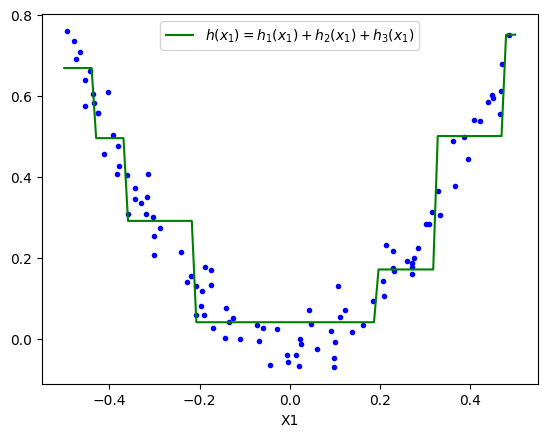

In [21]:
X1 = np.linspace(start=-0.5,stop=0.5,num=100).reshape(-1,1)
y1 = sum(tree.predict(X1) for tree in [tree_reg1,tree_reg2,tree_reg3])
plt.plot(X,y,"b.")
plt.plot(X1,y1,"g-",label="$h(x_1) = h_1(x_1) + h_2(x_1) + h_3(x_1)$")
plt.legend()
plt.xlabel("X1")
plt.show()

In [22]:
from sklearn.ensemble import GradientBoostingRegressor

In [23]:
gbr = GradientBoostingRegressor(n_estimators=3,learning_rate=1.0,max_depth=3,random_state=42)
gbr.fit(X,y)

,loss,'squared_error'
,learning_rate,1.0
,n_estimators,3
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [24]:
gbr.predict(X_new)

array([ 0.54626167, -0.05185738,  0.71148342])

In [25]:
# Early stopping
gbr_best = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=2,
    validation_fraction=0.1, # 0.1 % is for validate the tree
    n_iter_no_change=10, # stop if no improvement for 10 trees
    random_state=42
)
gbr_best.fit(X,y)

,loss,'squared_error'
,learning_rate,0.05
,n_estimators,500
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,2
,min_impurity_decrease,0.0
,init,None


In [27]:
gbr_best.n_estimators_

92

### HistGradientBoosting

HistGradientBoosting is a faster, scalable version of Gradient Boosting that uses histogram-based splits instead of exact numeric splits. It is scikit-learn’s production-grade gradient boosting.\
age values → bins:
[18–25], [26–35], [36–45], ...

In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
import tarfile
import urllib.request
from pathlib import Path

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()
train_set, test_set = train_test_split(housing,test_size=0.2,random_state=42)

In [32]:
housing_labels = train_set["median_house_value"]
housing = train_set.drop("median_house_value",axis=1)

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder

In [35]:
preprocessing = make_column_transformer(
    (OrdinalEncoder(),["ocean_proximity"]),
    remainder="passthrough"
)

In [36]:
hgb_reg = make_pipeline(
    preprocessing,
    HistGradientBoostingRegressor(categorical_features=[0],random_state=42)
)
hgb_reg.fit(housing, housing_labels)

,steps,"[('columntransformer', ...), ('histgradientboostingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinalencoder', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


why we used OrdinalEncoder()? ocean_proximity is categorical. HistGradientBoosting expects: categorical features → integer encoded\
OrdinalEncoder converts:
"NEAR BAY" → 0
"INLAND" → 1

Why categorical_features=[0]? After transformation:ocean_proximity becomes column 0 . You must explicitly tell HGB: “This column is categorical”.Then the algorithm:Uses category-aware splits, Doesn’t treat categories as ordered numbers. 

In [37]:
from sklearn.model_selection import cross_val_score

In [38]:
hgb_reg = -cross_val_score(hgb_reg,housing,housing_labels,scoring="neg_root_mean_squared_error",cv=10)
pd.Series(hgb_reg).describe()

count       10.000000
mean     47613.307194
std       1295.422509
min      44963.213061
25%      47001.233485
50%      48000.963564
75%      48488.093243
max      49176.368465
dtype: float64

### Stacking

In [39]:
from sklearn.ensemble import StackingClassifier

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [43]:
# data 
from sklearn.datasets import load_iris
iris = load_iris()
X_train,y_train = iris.data[:,1:3], iris.target

In [44]:
# defining base learners
myclf1 = LogisticRegression(random_state=42)
myclf2 = RandomForestClassifier(random_state=42)
myclf3 = SVC(probability=True, random_state=42)
# define meta model
meta_model = RandomForestClassifier(random_state=43)
# stacking clf
stacking_clf = StackingClassifier(
    estimators=[
        ('lr', myclf1),
        ('rf', myclf2),
        ('svc', myclf3)
    ],
    final_estimator=meta_model,
    cv=5  # number of cross-validation folds
)
stacking_clf.fit(X_train, y_train)

,estimators,"[('lr', ...), ('rf', ...), ...]"
,final_estimator,RandomForestC...ndom_state=43)
,cv,5
,stack_method,'auto'
,n_jobs,None
,passthrough,False
,verbose,0
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [45]:
from sklearn.model_selection import cross_val_score

In [49]:
for model,name in zip([myclf1,myclf2,myclf3,meta_model],["lr","rf","svc","meta_model(rf)"]):
    score = cross_val_score(model,X_train,y_train,scoring="accuracy")
    print(f"{name}:  {score.mean()}")

lr:  0.9533333333333334
rf:  0.9399999999999998
svc:  0.9533333333333334
meta_model(rf):  0.9399999999999998
